# Gillespie kMC of a pseudo-first-order decay

**Reaction:** A + B → C + B, with B in large excess.

Because [B] barely changes, the rate law simplifies:

$$\frac{d[A]}{dt} = -k[A][B] \approx -k'[A], \qquad k' = k[B]$$

so deterministically $[A](t) = [A]_0 e^{-k't}$ (*pseudo*-first-order).

With only a few molecules, decay is random. The **Gillespie direct method** simulates this exactly:

1. Total event rate (propensity): $a = k' N$
2. Waiting time to next event: $\tau = -\ln(u)/a$, with $u$ uniform on (0, 1]
3. Apply the event: $N \to N-1$
4. Repeat until $N = 0$

Below we run it, then check it against the exact theory.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from gillespie_decay import (effective_rate, simulate_decay, simulate_ensemble,
                             analytical_mean, analytical_std)

K, CONC_B = 0.1, 0.5            # k in 1/(M s), [B] in M
K_EFF = effective_rate(K, CONC_B)
N0 = 100
print(f"k' = {K_EFF} 1/s, half-life = {np.log(2)/K_EFF:.1f} s")

k' = 0.05 1/s, half-life = 13.9 s


## 1. One trajectory
Each step down is one molecule reacting. Note the steps get *longer* as fewer molecules remain, because the propensity $k'N$ shrinks.

first 5 event times: [0.203 0.266 0.275 0.278 0.628]
last event time: 178.4 s


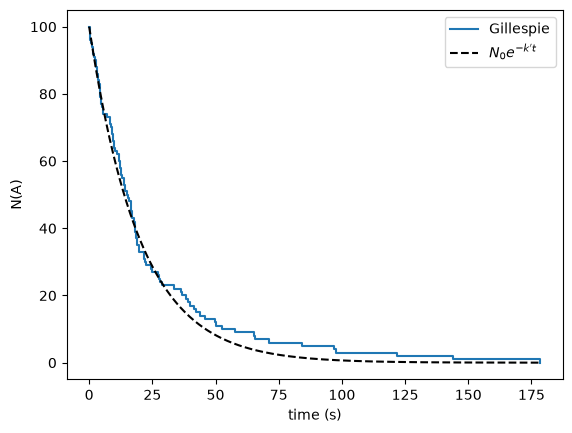

In [2]:
rng = np.random.default_rng(0)
times, counts = simulate_decay(N0, K_EFF, rng)
print("first 5 event times:", np.round(times[1:6], 3))
print("last event time:", round(times[-1], 1), "s")

t = np.linspace(0, times[-1], 400)
plt.step(times, counts, where="post", label="Gillespie")
plt.plot(t, analytical_mean(t, N0, K_EFF), "k--", label=r"$N_0 e^{-k't}$")
plt.xlabel("time (s)"); plt.ylabel("N(A)"); plt.legend(); plt.show()

## 2. Many trajectories: the average recovers the rate law
Every molecule survives to time $t$ independently with probability $e^{-k't}$, so $N(t)$ is Binomial($N_0$, $e^{-k't}$): mean $N_0 p$, variance $N_0 p (1-p)$.

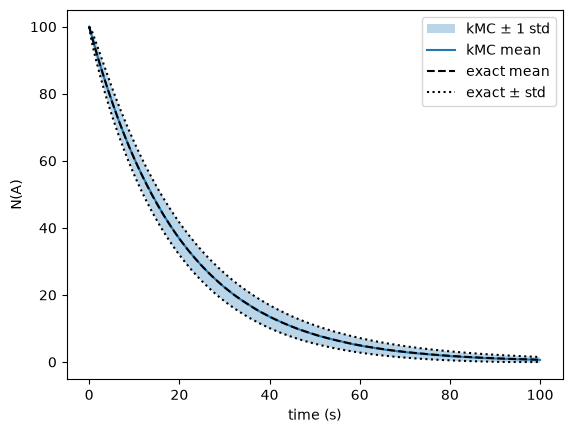

In [3]:
grid = np.linspace(0, 100, 200)
ens = simulate_ensemble(N0, K_EFF, n_runs=500, grid=grid, seed=1)
mean, std = ens.mean(axis=0), ens.std(axis=0, ddof=1)

plt.fill_between(grid, mean-std, mean+std, alpha=0.3, label="kMC ± 1 std")
plt.plot(grid, mean, label="kMC mean")
plt.plot(grid, analytical_mean(grid, N0, K_EFF), "k--", label="exact mean")
plt.plot(grid, analytical_mean(grid, N0, K_EFF) + analytical_std(grid, N0, K_EFF), "k:", label="exact ± std")
plt.plot(grid, np.clip(analytical_mean(grid, N0, K_EFF) - analytical_std(grid, N0, K_EFF), 0, None), "k:")
plt.xlabel("time (s)"); plt.ylabel("N(A)"); plt.legend(); plt.show()

## 3. Recover $k'$ from the simulated data
On a log plot, exponential decay is a straight line with slope $-k'$.

true k' = 0.05, fitted k' = 0.0503


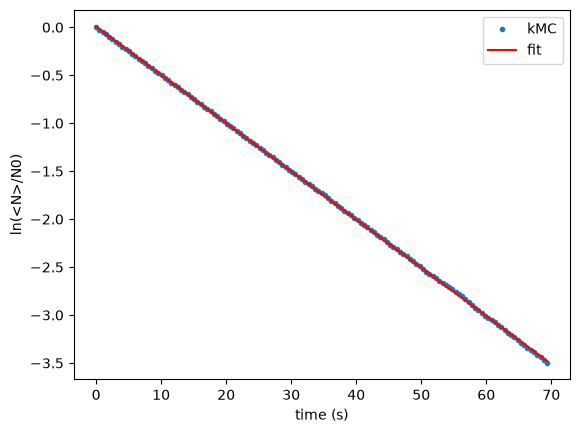

In [4]:
mask = mean >= 3
slope, intercept = np.polyfit(grid[mask], np.log(mean[mask]/N0), 1)
print(f"true k' = {K_EFF}, fitted k' = {-slope:.4f}")

plt.plot(grid[mask], np.log(mean[mask]/N0), "o", ms=3, label="kMC")
plt.plot(grid[mask], slope*grid[mask]+intercept, "r-", label="fit")
plt.xlabel("time (s)"); plt.ylabel("ln(<N>/N0)"); plt.legend(); plt.show()

## 4. Noise shrinks with system size
The relative fluctuation scales like $1/\sqrt{N_0}$ — so the deterministic law is the large-$N$ limit of the stochastic one.

In [5]:
t_half = np.log(2)/K_EFF
for n0 in [10, 100, 1000]:
    e = simulate_ensemble(n0, K_EFF, 300, np.array([t_half]), seed=2)[:, 0]
    print(f"N0={n0:5d}: relative std at t_half = {e.std(ddof=1)/e.mean():.3f}   (theory {1/np.sqrt(n0):.3f})")

N0=   10: relative std at t_half = 0.298   (theory 0.316)
N0=  100: relative std at t_half = 0.102   (theory 0.100)
N0= 1000: relative std at t_half = 0.032   (theory 0.032)
